[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package names to /root/nltk_data...
[nltk_data]   Package names is already up-to-date!


IVAN GOLUNOV WRITING STYLE ANALYSIS

Total links found: 122

Starting article collection...
[1/122] https://meduza.io/
[2/122] https://meduza.io/articles
[3/122] https://meduza.io/razbor
[4/122] https://meduza.io/podcasts
[5/122] https://meduza.io/en
[6/122] https://meduza.io/feature/2017/09/20/hristianskogo-gosudarstva-ne-suschestvuet-no-za-nim-vozmozhno-stoit-fsb
[7/122] https://meduza.io/feature/2016/11/07/lipy-za-200-tysyach
[8/122] https://meduza.io/feature/2017/01/19/moskva-zakupila-girlyandy-dlya-tverskoy-po-dva-milliona-rubley-oni-stoyat-v-pyat-raz-deshevle
[9/122] https://meduza.io/feature/2017/01/12/fuzhery-ot-bratiev-rotenbergov
[10/122] https://meduza.io/feature/2017/02/20/zavhoz-protiv-porno
[11/122] https://meduza.io/feature/2017/04/17/odna-absolyutno-schastlivaya-derevnya
[12/122] https://meduza.io/feature/2017/08/15/kto-pridumal-renovatsiyu
[13/122] https://meduza.io/feature/2018/12/28/penthaus-razmerom-s-dva-eliseevskih
[14/122] https://meduza.io/feature/2019/01/18/ic3

/tmp/ipykernel_1008/1388565516.py:487: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["date_parsed"] = pd.to_datetime(



EARLY VS CURRENT
period                Current     Early  Change_%
word_count           1536.138  1769.684   -13.197
sentence_count         86.121    99.018   -13.025
unique_words          805.448   930.474   -13.437
avg_sentence_length    16.912    17.409    -2.854
lexical_diversity       0.589     0.585     0.605
avg_word_length         6.065     6.158    -1.513
comma_count           135.569   149.930    -9.578
question_count          0.707     1.456   -51.454
exclamation_count       1.138     1.035     9.936
colon_count             7.172     7.474    -4.031
semicolon_count         5.500     5.263     4.500
dash_count             29.259    38.825   -24.639
punctuation_density     0.013     0.012     4.217

Saved style_features.csv


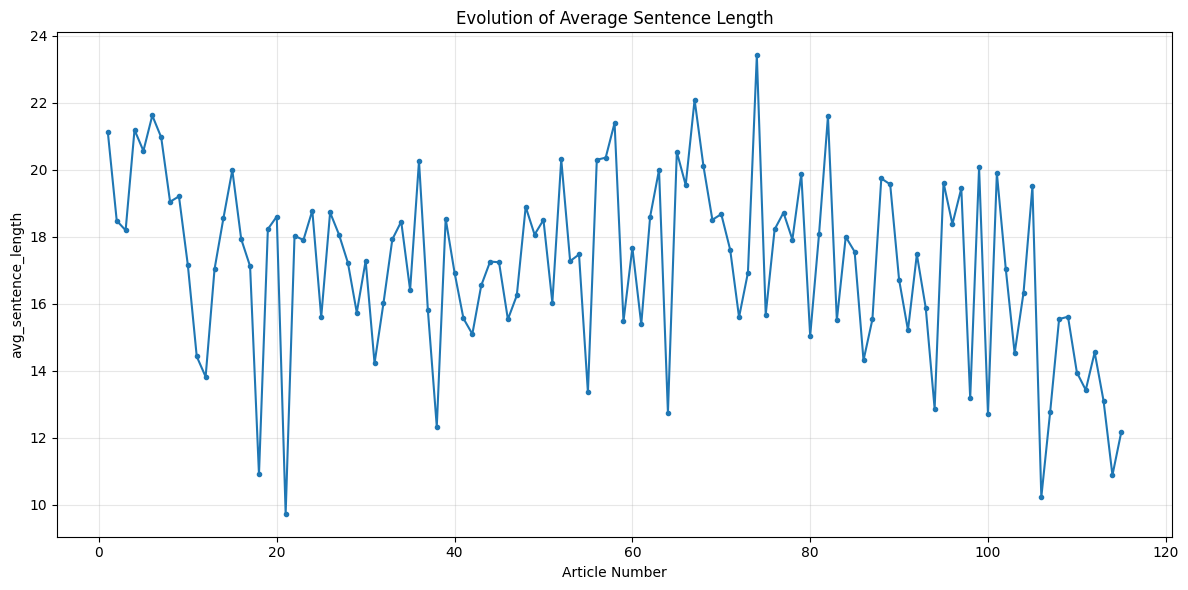

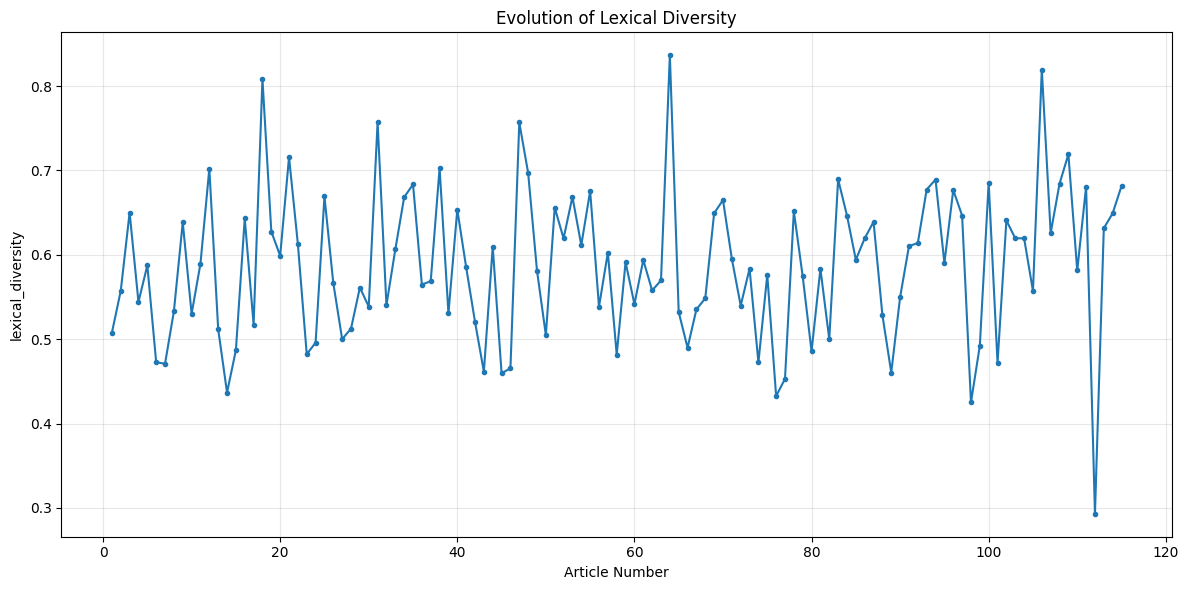

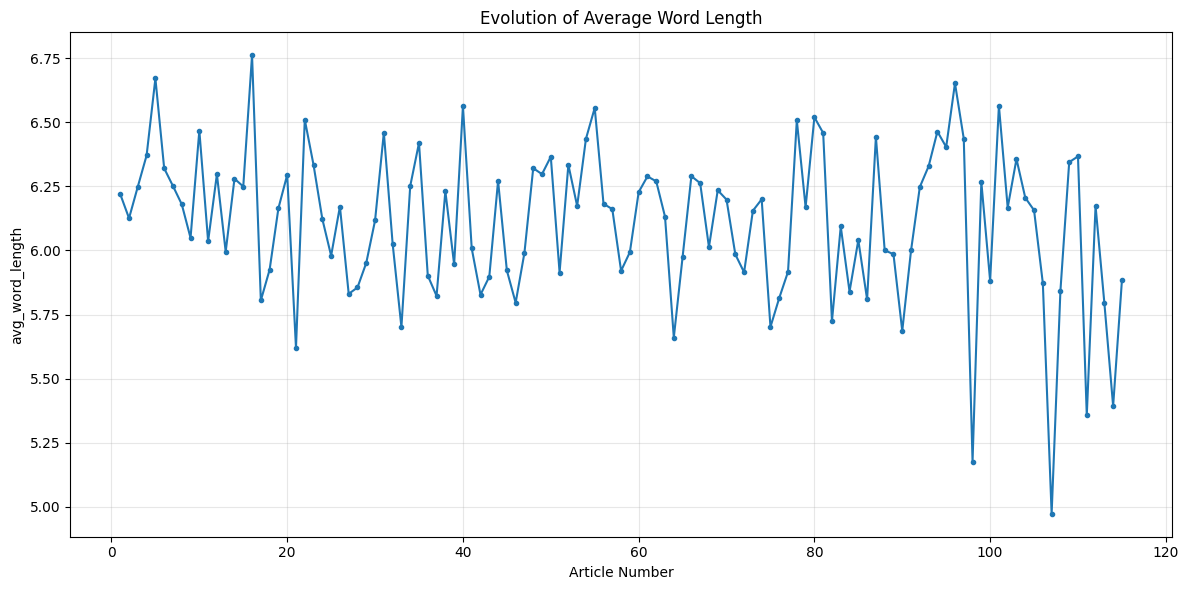

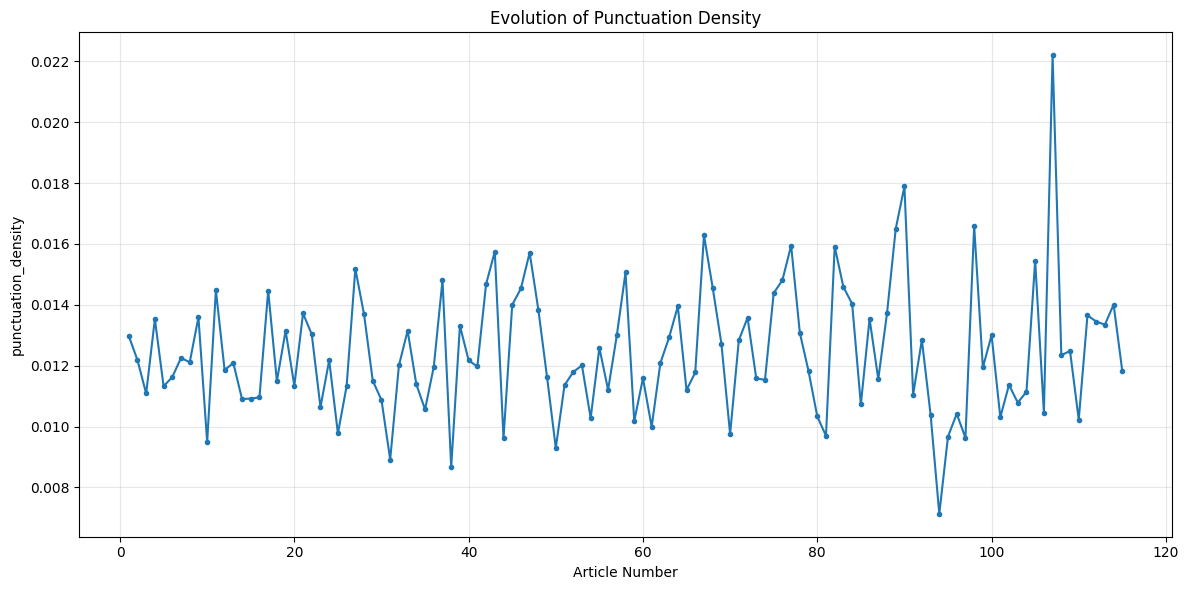

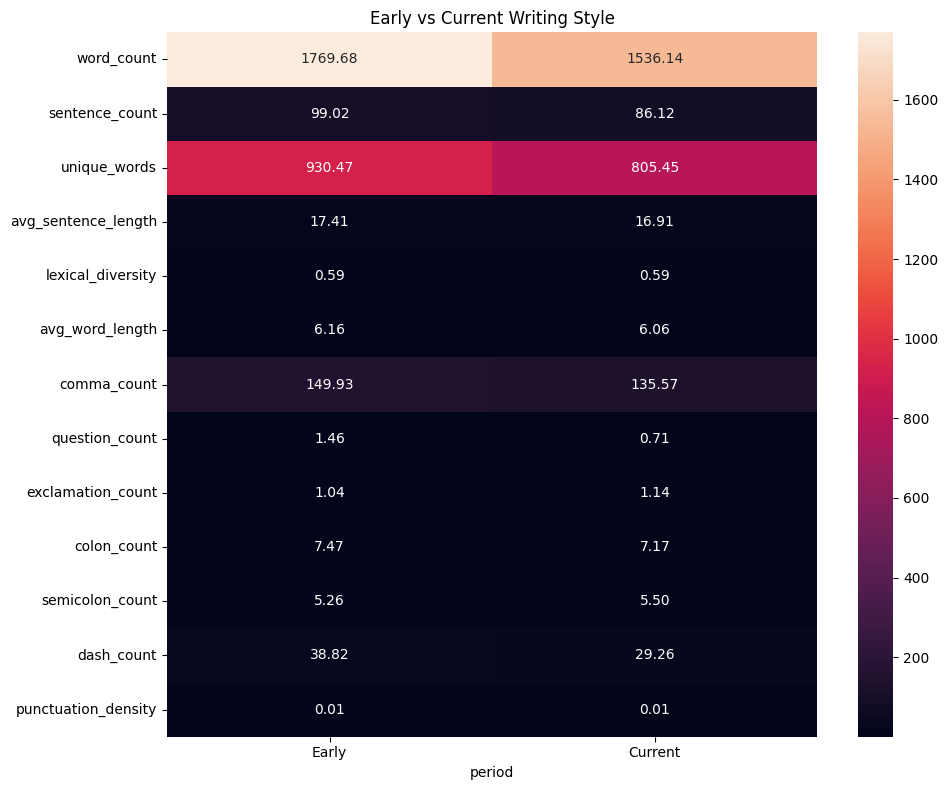


TF-IDF ANALYSIS

Top 30 stylistically important words:

года                      0.1220
рублей                    0.1079
его                       0.1026
как                       0.0992
году                      0.0958
для                       0.0927
компании                  0.0798
москвы                    0.0788
также                     0.0759
все                       0.0670
компания                  0.0660
был                       0.0632
после                     0.0621
россии                    0.0619
она                       0.0564
которые                   0.0529
было                      0.0522
они                       0.0503
который                   0.0498
несколько                 0.0498
только                    0.0496
медузе                    0.0496
были                      0.0490
или                       0.0485
уже                       0.0483
если                      0.0482
словам                    0.0477
есть                      0.0469
более              

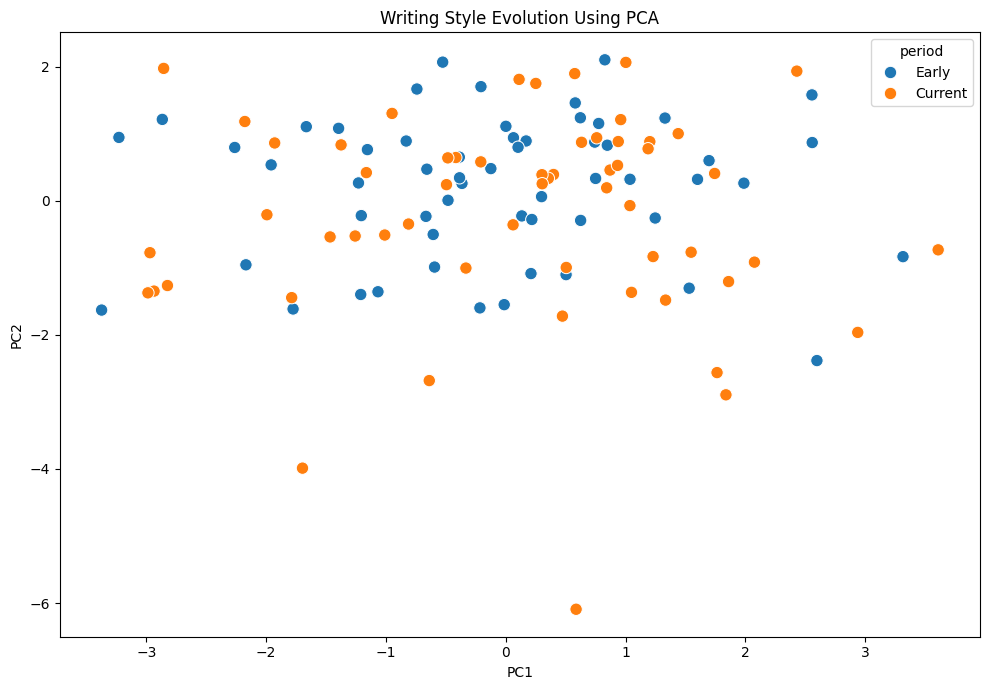



HIRING-SUPPORT WRITING PROFILE

Criterion                    Average Value       Score
Avg Sentence Length                   17.158       100.00/100
Lexical Diversity                      0.587       100.00/100
Avg Word Length                        6.111       100.00/100
Punctuation Density                    0.012       100.00/100
Writing Consistency                    0.120        88.00/100

Overall Writing Compatibility Score: 97.60/100

INTERPRETATION OF RESULTS

The comparison between Ivan Golunov's earlier and current articles
indicates a moderate evolution in his writing style. The average article
length decreased by approximately 13.2%, from 1,769.7 words in the
earlier days to 1,536.1 words in the current days. The number of
sentences also decreased by approximately 13.0%, suggesting that his
recent articles are more concise.

The average sentence length decreased by only 2.85%, and the average
word length changed by only 1.51%, suggesting that the structure of his
sentence

In [2]:
!pip install requests beautifulsoup4 pandas numpy matplotlib seaborn scikit-learn nltk textstat langdetect

import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import re
import time
import os

import nltk
import textstat

import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity

# NLTK

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("names")

# SETTINGS

AUTHOR = "Ivan Golunov"

# Official Meduza page containing Golunov's CC-licensed work
SOURCE_PAGE = (
    "https://meduza.io/feature/2019/06/08/"
    "my-prizyvaem-vseh-perepechatyvat-polnye-teksty-rassledovaniy-ivana-golunova/"
)

OUTPUT_DIR = "graphs"

os.makedirs(OUTPUT_DIR, exist_ok=True)

HEADERS = {
    "User-Agent": "AcademicResearchStyleAnalysis/1.0"
}


# 1. DOWNLOAD PAGE

def download_page(url):

    try:

        response = requests.get(
            url,
            headers=HEADERS,
            timeout=20
        )

        if response.status_code == 200:

            return response.text

        else:

            print(
                "Failed:",
                response.status_code,
                url
            )

            return None

    except Exception as e:

        print("Error:", e)

        return None


# 2. COLLECT ARTICLE LINKS

def collect_article_links():

    print("\nCollecting article links...")

    html = download_page(SOURCE_PAGE)

    if html is None:
        return []

    soup = BeautifulSoup(
        html,
        "html.parser"
    )

    links = []

    for a in soup.find_all("a", href=True):

        href = a["href"]

        # Convert relative URL to full URL
        if href.startswith("/"):

            href = "https://meduza.io" + href

        # We only want Meduza pages
        if not href.startswith("https://meduza.io"):

            continue

        # Avoid the source page itself
        if href == SOURCE_PAGE:
            continue

        # Avoid duplicate links
        if href not in links:

            links.append(href)

    print(
        "Total links found:",
        len(links)
    )

    return links


# 3. DOWNLOAD ARTICLE

def scrape_article(url):

    html = download_page(url)

    if html is None:
        return None

    soup = BeautifulSoup(
        html,
        "html.parser"
    )

    # TITLE

    title = ""

    title_tag = soup.find("h1")

    if title_tag:

        title = title_tag.get_text(
            " ",
            strip=True
        )

    # DATE

    date = ""

    time_tag = soup.find("time")

    if time_tag:

        date = (
            time_tag.get("datetime")
            or time_tag.get_text(
                " ",
                strip=True
            )
        )

    # ARTICLE BODY

    article = soup.find("article")

    if article:

        paragraphs = article.find_all("p")

    else:

        paragraphs = soup.find_all("p")

    text_parts = []

    for p in paragraphs:

        text = p.get_text(
            " ",
            strip=True
        )

        if text:

            text_parts.append(text)

    text = " ".join(text_parts)

    # CLEAN TEXT

    text = clean_text(text)

    # Ignore extremely short pages
    if len(text.split()) < 100:

        return None

    return {
        "author": AUTHOR,
        "title": title,
        "date": date,
        "url": url,
        "text": text
    }


# 4. CLEAN TEXT

def clean_text(text):

    # Remove excessive spaces
    text = re.sub(
        r"\s+",
        " ",
        text
    )

    # Remove leading/trailing spaces
    text = text.strip()

    return text


# 5. TOKENIZE RUSSIAN TEXT

def tokenize(text):

    words = re.findall(
        r"[А-Яа-яЁёA-Za-z]+",
        text.lower()
    )

    return words


# 6. EXTRACT STYLE FEATURES

def extract_features(text):

    words = tokenize(text)

    sentences = re.split(
        r"[.!?]+",
        text
    )

    sentences = [
        s.strip()
        for s in sentences
        if s.strip()
    ]

    word_count = len(words)

    sentence_count = len(sentences)

    unique_words = len(
        set(words)
    )

    # Average sentence length

    if sentence_count > 0:

        avg_sentence_length = (
            word_count /
            sentence_count
        )

    else:

        avg_sentence_length = 0

    # Lexical diversity

    if word_count > 0:

        lexical_diversity = (
            unique_words /
            word_count
        )

    else:

        lexical_diversity = 0

    # Word length

    if word_count > 0:

        avg_word_length = np.mean(
            [
                len(word)
                for word in words
            ]
        )

    else:

        avg_word_length = 0

    # Punctuation

    comma_count = text.count(",")

    question_count = text.count("?")

    exclamation_count = text.count("!")

    colon_count = text.count(":")

    semicolon_count = text.count(";")

    dash_count = text.count("—")

    # Character count

    character_count = len(text)

    # Punctuation density

    if character_count > 0:

        punctuation_density = (
            comma_count +
            question_count +
            exclamation_count +
            colon_count +
            semicolon_count
        ) / character_count

    else:

        punctuation_density = 0

    return {

        "word_count":
            word_count,

        "sentence_count":
            sentence_count,

        "unique_words":
            unique_words,

        "avg_sentence_length":
            avg_sentence_length,

        "lexical_diversity":
            lexical_diversity,

        "avg_word_length":
            avg_word_length,

        "comma_count":
            comma_count,

        "question_count":
            question_count,

        "exclamation_count":
            exclamation_count,

        "colon_count":
            colon_count,

        "semicolon_count":
            semicolon_count,

        "dash_count":
            dash_count,

        "punctuation_density":
            punctuation_density
    }


# 7. COLLECT ARTICLES

def collect_articles():

    links = collect_article_links()

    articles = []

    print(
        "\nStarting article collection..."
    )

    for i, url in enumerate(links):

        print(
            f"[{i+1}/{len(links)}]",
            url
        )

        article = scrape_article(url)

        if article:

            articles.append(article)

        # Be polite to the server
        time.sleep(2)

    print(
        "\nArticles successfully collected:",
        len(articles)
    )

    return articles


# 8. SAVE ARTICLES

def save_articles(articles):

    df = pd.DataFrame(
        articles
    )

    df.to_csv(
        "articles.csv",
        index=False,
        encoding="utf-8-sig"
    )

    print(
        "\nSaved articles.csv"
    )

    return df


# 9. CREATE STYLE DATASET

def create_style_dataset(df):

    rows = []

    for index, row in df.iterrows():

        features = extract_features(
            row["text"]
        )

        features["article_number"] = (
            index + 1
        )

        features["title"] = (
            row["title"]
        )

        features["date"] = (
            row["date"]
        )

        features["url"] = (
            row["url"]
        )

        rows.append(features)

    style_df = pd.DataFrame(rows)

    return style_df


# 10. SORT ARTICLES CHRONOLOGICALLY

def sort_articles(df):

    df["date_parsed"] = pd.to_datetime(
        df["date"],
        errors="coerce"
    )

    df = df.sort_values(
        "date_parsed"
    )

    df = df.reset_index(
        drop=True
    )

    df["article_number"] = (
        df.index + 1
    )

    return df


# 11. EARLY VS CURRENT

def compare_early_current(style_df):

    # Make sure articles are ordered
    style_df = style_df.sort_values(
        "date"
    ).reset_index(
        drop=True
    )

    total = len(style_df)

    # First half
    midpoint = total // 2

    style_df["period"] = "Early"

    style_df.loc[
        midpoint:,
        "period"
    ] = "Current"

    numerical_features = [

        "word_count",

        "sentence_count",

        "unique_words",

        "avg_sentence_length",

        "lexical_diversity",

        "avg_word_length",

        "comma_count",

        "question_count",

        "exclamation_count",

        "colon_count",

        "semicolon_count",

        "dash_count",

        "punctuation_density"

    ]

    comparison = (
        style_df
        .groupby("period")[numerical_features]
        .mean()
    )

    comparison = comparison.T

    comparison["Change_%"] = (

        (
            comparison["Current"]
            -
            comparison["Early"]
        )

        /

        comparison["Early"].replace(
            0,
            np.nan
        )

    ) * 100

    comparison.to_csv(
        "comparison.csv"
    )

    print(
        "\n=============================="
    )

    print(
        "EARLY VS CURRENT"
    )

    print(
        "=============================="
    )

    print(
        comparison.round(3)
    )

    return style_df, comparison


# 12. PLOT STYLE EVOLUTION

def plot_feature(
    df,
    column,
    title,
    filename
):

    plt.figure(
        figsize=(12, 6)
    )

    plt.plot(
        df["article_number"],
        df[column],
        marker="o",
        markersize=3
    )

    plt.xlabel(
        "Article Number"
    )

    plt.ylabel(
        column
    )

    plt.title(
        title
    )

    plt.grid(
        True,
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/{filename}",
        dpi=300
    )

    plt.show()


# 13. TF-IDF

def tfidf_analysis(df):

    print(
        "\n=============================="
    )

    print(
        "TF-IDF ANALYSIS"
    )

    print(
        "=============================="
    )

    documents = df["text"].tolist()

    vectorizer = TfidfVectorizer(

        max_features=300,

        min_df=2,

        max_df=0.95,

        token_pattern=r"(?u)\b[А-Яа-яЁёA-Za-z]{3,}\b"

    )

    X = vectorizer.fit_transform(
        documents
    )

    words = (
        vectorizer
        .get_feature_names_out()
    )

    # Average TF-IDF across articles
    scores = np.asarray(
        X.mean(axis=0)
    ).flatten()

    word_scores = list(
        zip(
            words,
            scores
        )
    )

    word_scores.sort(
        key=lambda x: x[1],
        reverse=True
    )

    print(
        "\nTop 30 stylistically important words:\n"
    )

    for word, score in word_scores[:30]:

        print(
            f"{word:25s} {score:.4f}"
        )

    return X


# 14. PCA STYLE VISUALIZATION

def pca_analysis(df):

    features = [

        "avg_sentence_length",

        "lexical_diversity",

        "avg_word_length",

        "punctuation_density",

        "word_count"

    ]

    X = df[features].fillna(0)

    scaler = StandardScaler()

    X_scaled = scaler.fit_transform(
        X
    )

    pca = PCA(
        n_components=2
    )

    components = pca.fit_transform(
        X_scaled
    )

    df["PC1"] = components[:, 0]

    df["PC2"] = components[:, 1]

    plt.figure(
        figsize=(10, 7)
    )

    sns.scatterplot(

        data=df,

        x="PC1",

        y="PC2",

        hue="period",

        s=80

    )

    plt.title(
        "Writing Style Evolution Using PCA"
    )

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/pca_style_evolution.png",
        dpi=300
    )

    plt.show()


# 15. HEATMAP

def create_heatmap(
    comparison
):

    plt.figure(
        figsize=(10, 8)
    )

    sns.heatmap(

        comparison[
            ["Early", "Current"]
        ],

        annot=True,

        fmt=".2f"

    )

    plt.title(
        "Early vs Current Writing Style"
    )

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/early_current_heatmap.png",
        dpi=300
    )

    plt.show()


# 16. HIRING-SUPPORT ANALYSIS

def create_hiring_profile(style_df):
    """
    Create a writing-style compatibility profile.
    This is supporting evidence, not an automatic hiring decision.
    """

    # Example requirements for a professional writing role.
    # These can be changed to match the actual company's requirements.
    targets = {
        "avg_sentence_length": (12, 25),
        "lexical_diversity": (0.30, 0.60),
        "avg_word_length": (4, 8),
        "punctuation_density": (0.005, 0.05)
    }

    profile = {}

    for feature, (low, high) in targets.items():
        value = style_df[feature].mean()

        if low <= value <= high:
            score = 100
        elif value < low:
            score = max(0, 100 - ((low - value) / low) * 100)
        else:
            score = max(0, 100 - ((value - high) / high) * 100)

        profile[feature] = {
            "value": value,
            "score": score
        }

    # Consistency of sentence length, vocabulary diversity,
    # and word length across articles.
    consistency_features = [
        "avg_sentence_length",
        "lexical_diversity",
        "avg_word_length"
    ]

    cvs = []

    for feature in consistency_features:
        mean_value = style_df[feature].mean()

        if mean_value != 0:
            cvs.append(
                style_df[feature].std() / abs(mean_value)
            )

    average_cv = np.mean(cvs) if cvs else 0
    consistency_score = max(
        0,
        min(100, 100 - average_cv * 100)
    )

    profile["consistency"] = {
        "value": average_cv,
        "score": consistency_score
    }

    return profile


def hiring_support_analysis(style_df):
    """
    Generate a human-readable writing profile for hiring support.
    """

    profile = create_hiring_profile(style_df)

    print("\n=========================================================")
    print("HIRING-SUPPORT WRITING PROFILE")
    print("=========================================================")

    print("\nCriterion                    Average Value       Score")

    for feature, result in profile.items():

        label = (
            "Writing Consistency"
            if feature == "consistency"
            else feature.replace("_", " ").title()
        )

        print(
            f"{label:28s}"
            f"{result['value']:16.3f}       "
            f"{result['score']:6.2f}/100"
        )

    overall_score = np.mean([
        result["score"]
        for result in profile.values()
    ])

    print(
        f"\nOverall Writing Compatibility Score: "
        f"{overall_score:.2f}/100"
    )

    return profile, overall_score


def run_hiring_analysis(style_df):

    # General writing-style compatibility
    profile, overall_score = hiring_support_analysis(
        style_df
    )
    return profile, overall_score


# 17. FINAL INTERPRETATION

def print_interpretation():

    print("""
=========================================================
INTERPRETATION OF RESULTS
=========================================================

The comparison between Ivan Golunov's earlier and current articles
indicates a moderate evolution in his writing style. The average article
length decreased by approximately 13.2%, from 1,769.7 words in the
earlier days to 1,536.1 words in the current days. The number of
sentences also decreased by approximately 13.0%, suggesting that his
recent articles are more concise.

The average sentence length decreased by only 2.85%, and the average
word length changed by only 1.51%, suggesting that the structure of his
sentences and word-level complexity have remained relatively stable.
The number of unique words decreased by approximately 13.4%, while
lexical diversity increased slightly by 0.61%, indicating that the
smaller vocabulary in the current articles is largely associated with
their shorter sentence length rather than a decrease in his vocabulary
richness.

Question-mark usage decreased significantly by approximately 51.5%,
while dash usage decreased by approximately 24.6%. This may indicate a
shift toward more declarative writing over rhetorical writing. However,
these changes may also be influenced by differences in article topics
or genres.

Overall, the results suggest that Golunov's writing has become more
concise over time, while his core linguistic characteristics,
particularly sentence length, word length, and lexical diversity, have
remained relatively stable. Therefore, the analysis indicates gradual
stylistic evolution rather than a complete transformation of his
writing style.

HIRING DECISION:

The analysis indicates that Golunov's writing strongly matches the defined
characteristics for the writing role, particularly in sentence length,
vocabulary richness, word-level complexity, and punctuation patterns.
His writing consistency is slightly lower at 88/100, but this does not
substantially reduce the overall compatibility.

""")


# 16. MAIN PROGRAM

def main():

    print(
        "======================================"
    )

    print(
        "IVAN GOLUNOV WRITING STYLE ANALYSIS"
    )

    print(
        "======================================"
    )

    # Collect

    articles = collect_articles()

    if len(articles) == 0:

        print(
            "No articles collected."
        )

        return

    # Save raw articles

    articles_df = save_articles(
        articles
    )

    # Sort chronologically

    articles_df = sort_articles(
        articles_df
    )

    # Extract style features

    style_df = create_style_dataset(
        articles_df
    )

    # Merge date information correctly
    style_df["date"] = (
        articles_df["date_parsed"]
        .values
    )

    # Compare early/current

    style_df, comparison = (
        compare_early_current(
            style_df
        )
    )

    # Save feature dataset

    style_df.to_csv(
        "style_features.csv",
        index=False,
        encoding="utf-8-sig"
    )

    print(
        "\nSaved style_features.csv"
    )

    # Graphs

    plot_feature(

        style_df,

        "avg_sentence_length",

        "Evolution of Average Sentence Length",

        "sentence_length.png"

    )

    plot_feature(

        style_df,

        "lexical_diversity",

        "Evolution of Lexical Diversity",

        "lexical_diversity.png"

    )

    plot_feature(

        style_df,

        "avg_word_length",

        "Evolution of Average Word Length",

        "word_length.png"

    )

    plot_feature(

        style_df,

        "punctuation_density",

        "Evolution of Punctuation Density",

        "punctuation_density.png"

    )

    # Heatmap

    create_heatmap(
        comparison
    )

    # TF-IDF

    tfidf_analysis(
        articles_df
    )

    # PCA

    pca_analysis(
        style_df
    )

    print(
        "\n======================================"
    )

    # Hiring-support analysis

    run_hiring_analysis(
        style_df
    )

    # Final interpretation

    print_interpretation()

    print(
        "ANALYSIS COMPLETE"
    )

    print(
        "======================================"
    )


# RUN

if __name__ == "__main__":

    main()
